In [2]:
import pandas as pd

df = pd.read_excel("Real estate valuation data set.xlsx")

df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


In [3]:
# Check duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check the range of the two main variables
print(df[[
    "X3 distance to the nearest MRT station",
    "Y house price of unit area"
]].agg(["min", "max"]))

Duplicate rows: 0
     X3 distance to the nearest MRT station  Y house price of unit area
min                                23.38284                         7.6
max                              6488.02100                       117.5


In [4]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


In [5]:
# Select the two variables
distance = df["X3 distance to the nearest MRT station"]
price = df["Y house price of unit area"]

# Descriptive statistics
df[[
    "X3 distance to the nearest MRT station",
    "Y house price of unit area"
]].describe()

,X3 distance to the nearest MRT station,Y house price of unit area
count,414.000000,414.000000
mean,1083.885689,37.980193
std,1262.109595,13.606488
min,23.382840,7.600000
25%,289.324800,27.700000
50%,492.231300,38.450000
75%,1454.279000,46.600000
max,6488.021000,117.500000


In [6]:
distance = df["X3 distance to the nearest MRT station"]
price = df["Y house price of unit area"]

print("Number of observations:", len(df))
print("Missing values:")
print(df[[
    "X3 distance to the nearest MRT station",
    "Y house price of unit area"
]].isna().sum())


Number of observations: 414
Missing values:
X3 distance to the nearest MRT station    0
Y house price of unit area                0
dtype: int64


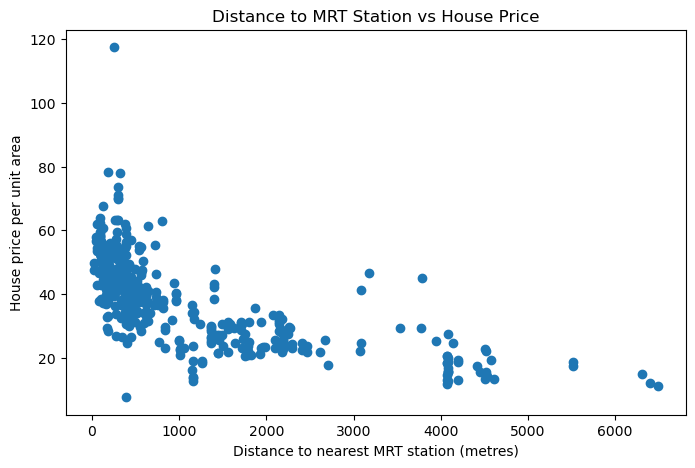

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(distance, price)

plt.xlabel("Distance to nearest MRT station (metres)")
plt.ylabel("House price per unit area")
plt.title("Distance to MRT Station vs House Price")

plt.show()

In [8]:
correlation = distance.corr(price)

print("Pearson correlation:", correlation)

Pearson correlation: -0.6736128553689185


In [16]:
# Calculate Pearson's correlation coefficient.
from scipy.stats import pearsonr

pearson_r, pearson_p = pearsonr(distance, price)

print("Pearson correlation:", pearson_r)
print("Pearson p-value:", pearson_p)

Pearson correlation: -0.6736128553689179
Pearson p-value: 4.639825030362697e-56


In [17]:
# Calculate Spearman's rank correlation coefficient.
from scipy.stats import spearmanr
spearman_r, spearman_p = spearmanr(distance, price)

print("Spearman correlation:", spearman_r)
print("Spearman p-value:", spearman_p)


Spearman correlation: -0.7759483354370685
Spearman p-value: 1.8116573146108762e-84


In [18]:
# Summarise the correlation results in a table.
results = pd.DataFrame({
    "Method": ["Pearson", "Spearman"],
    "Correlation": [pearson_r, spearman_r],
    "P-value": [pearson_p, spearman_p]
})

results


,Method,Correlation,P-value
0,Pearson,-0.673613,4.639825e-56
1,Spearman,-0.775948,1.811657e-84


In [19]:
# Create a new dataset excluding the extreme price observation.
df_no_outlier = df[
    df["Y house price of unit area"] != 117.5
].copy()

print("Original sample size:", len(df))
print("New sample size:", len(df_no_outlier))


Original sample size: 414
New sample size: 413


In [20]:
from scipy.stats import pearsonr, spearmanr

# Select variables from the new dataset
distance_new = df_no_outlier[
    "X3 distance to the nearest MRT station"
]

price_new = df_no_outlier[
    "Y house price of unit area"
]

# Recalculate Pearson
pearson_new, pearson_p_new = pearsonr(
    distance_new, price_new
)

# Recalculate Spearman
spearman_new, spearman_p_new = spearmanr(
    distance_new, price_new
)

print("Pearson without outlier:", pearson_new)
print("Pearson p-value:", pearson_p_new)

print("Spearman without outlier:", spearman_new)
print("Spearman p-value:", spearman_p_new)


Pearson without outlier: -0.6940089730153479
Pearson p-value: 1.281088574046852e-60
Spearman without outlier: -0.7757908059186034
Spearman p-value: 3.262949196341888e-84


In [21]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr

x_col = "X3 distance to the nearest MRT station"
y_col = "Y house price of unit area"

# Original data
original = df[[x_col, y_col]].dropna()

# Exclude the extreme observation
without_outlier = original[
    original[y_col] != 117.5
]

# Calculate correlations
p_original = pearsonr(original[x_col], original[y_col])
s_original = spearmanr(original[x_col], original[y_col])

p_new = pearsonr(without_outlier[x_col], without_outlier[y_col])
s_new = spearmanr(without_outlier[x_col], without_outlier[y_col])

# Create comparison table
comparison = pd.DataFrame({
    "Method": ["Pearson", "Spearman"],
    "Original": [p_original.statistic, s_original.statistic],
    "Without 117.5": [p_new.statistic, s_new.statistic],
    "Change": [
        p_new.statistic - p_original.statistic,
        s_new.statistic - s_original.statistic
    ],
    "Original p-value": [p_original.pvalue, s_original.pvalue],
    "New p-value": [p_new.pvalue, s_new.pvalue]
})

print("Original sample:", len(original))
print("Reduced sample:", len(without_outlier))

display(comparison.round(4))


Original sample: 414
Reduced sample: 413


,Method,Original,Without 117.5,Change,Original p-value,New p-value
0,Pearson,-0.6736,-0.6940,-0.0204,0.0,0.0
1,Spearman,-0.7759,-0.7758,0.0002,0.0,0.0
